# Analisis dan Deteksi Nada DTMF (Dual Tone Multi Frequency) Telepon pada Sinyal Digital Menggunakan Transformasi Fourier

KELOMPOK 6

1.   Putri Sofiyatus Salwa (24031554112)
2.   Adisti Eka Nabilah (24031554119)
3. Cintiya Agustin Nareswari (24031554218)



**Tahap 1 Generate Dataset DTMF**


In [ ]:
import numpy as np
from scipy.io.wavfile import write
import os

output_folder = "data_dtmf"
os.makedirs(output_folder, exist_ok=True)

fs = 8000
duration = 0.5
t = np.linspace(0, duration, int(fs * duration), endpoint=False)

dtmf_freqs = {
    "1": (697, 1209), "2": (697, 1336), "3": (697, 1477),
    "4": (770, 1209), "5": (770, 1336), "6": (770, 1477),
    "7": (852, 1209), "8": (852, 1336), "9": (852, 1477),
    "*": (941, 1209), "0": (941, 1336), "#": (941, 1477)
}

for key, (f_low, f_high) in dtmf_freqs.items():
    signal = np.sin(2 * np.pi * f_low * t) + np.sin(2 * np.pi * f_high * t)
    signal = (signal / np.max(np.abs(signal))).astype(np.float32)
    filename = os.path.join(output_folder, f"dtmf_{key}.wav")
    write(filename, fs, signal)
    print(f"[Simpan] {filename}")

print("\nDataset DTMF dasar berhasil dibuat!")


[Simpan] data_dtmf/dtmf_1.wav
[Simpan] data_dtmf/dtmf_2.wav
[Simpan] data_dtmf/dtmf_3.wav
[Simpan] data_dtmf/dtmf_4.wav
[Simpan] data_dtmf/dtmf_5.wav
[Simpan] data_dtmf/dtmf_6.wav
[Simpan] data_dtmf/dtmf_7.wav
[Simpan] data_dtmf/dtmf_8.wav
[Simpan] data_dtmf/dtmf_9.wav
[Simpan] data_dtmf/dtmf_*.wav
[Simpan] data_dtmf/dtmf_0.wav
[Simpan] data_dtmf/dtmf_#.wav

Dataset DTMF dasar berhasil dibuat!


**TAHAP 2 — Upload rekaman (MP3 → WAV)**

In [ ]:
from google.colab import files

print("Silakan upload file MP3...")
uploaded = files.upload()


Silakan upload file MP3...


Saving rekaman sampel 4.mp3 to rekaman sampel 4 (1).mp3


**TAHAP 3 — Konversi MP3 ke WAV**

In [ ]:
!apt-get install ffmpeg -y
import os

mp3_file = list(uploaded.keys())[0]
wav_file = mp3_file.replace(".mp3", ".wav")

!ffmpeg -i "$mp3_file" "$wav_file"

print("Konversi selesai!")
print("File WAV:", wav_file)


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 1 not upgraded.
ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --

**TAHAP 4 — Play audio rekaman**

In [ ]:
from IPython.display import Audio
Audio(wav_file)


**TAHAP 4b — Visualisasi sinyal asli**

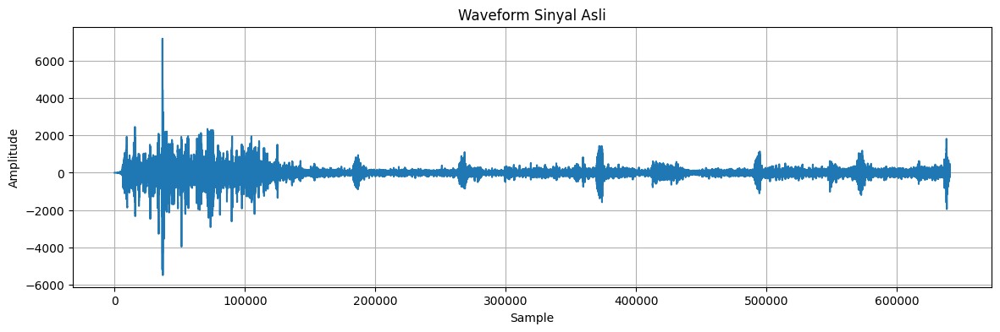

In [ ]:
from scipy.io.wavfile import read
import matplotlib.pyplot as plt

wav_file = "/content/rekaman sampel 4.wav"   # tentukan file

fs, data = read(wav_file)
sig = data.mean(axis=1) if data.ndim > 1 else data

plt.figure(figsize=(14, 4))
plt.plot(sig)
plt.title("Waveform Sinyal Asli")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()


**TAHAP 5 — Import library dan setup tabel frekuensi**

In [ ]:
import numpy as np
from scipy.io.wavfile import read
from scipy.signal import firwin, filtfilt
from scipy.fft import fft, fftfreq

DTMF_TABLE = {
    (697, 1209): "1", (697, 1336): "2", (697, 1477): "3",
    (770, 1209): "4", (770, 1336): "5", (770, 1477): "6",
    (852, 1209): "7", (852, 1336): "8", (852, 1477): "9",
    (941, 1209): "*", (941, 1336): "0", (941, 1477): "#"
}

LOW_FREQS  = np.array([697, 770, 852, 941])
HIGH_FREQS = np.array([1209, 1336, 1477])
FREQ_TOL   = 20.0


**TAHAP 6 — Filtering (Bandpass FIR)**

**TAHAP 6a - Perbandingan window untuk BPF**

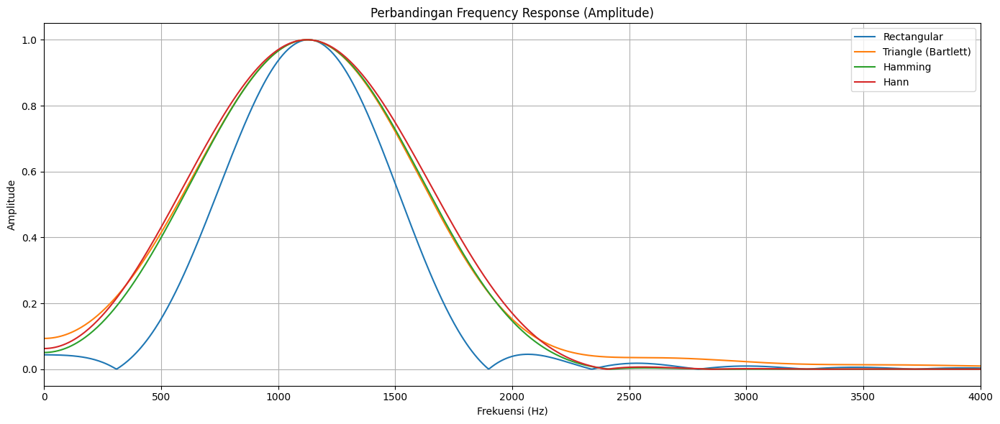

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

fs = 48000
low_cut = 650
high_cut = 1600
numtaps = 101

windows = {
    "Rectangular": "boxcar",
    "Triangle (Bartlett)": "bartlett",
    "Hamming": "hamming",
    "Hann": "hann"
}

plt.figure(figsize=(14, 6))
for name, win_type in windows.items():

    bpf = firwin(
        numtaps,
        [low_cut, high_cut],
        pass_zero=False,
        window=win_type,
        fs=fs
    )

    freqs, h = freqz(bpf, worN=4096, fs=fs)

    plt.plot(freqs, np.abs(h), label=name)

plt.title("Perbandingan Frequency Response (Amplitude)")
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 4000)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy.io.wavfile import read, write
from scipy.signal import firwin, filtfilt
from IPython.display import Audio

wav_file = "rekaman sampel 4.wav"

fs, data = read(wav_file)
sig = data.mean(axis=1) if data.ndim > 1 else data
sig = sig.astype(np.float32)

low_cut = 650
high_cut = 1600
numtaps = 101

windows = {
    "rectangular": "boxcar",
    "triangle": "bartlett",
    "hamming": "hamming",
    "hann": "hann"
}

filtered_outputs = {}

def apply_filter(sig, win_type):
    bpf = firwin(
        numtaps,
        [low_cut, high_cut],
        pass_zero=False,
        fs=fs,
        window=win_type
    )

    filtered = filtfilt(bpf, 1.0, sig)

    max_val = np.max(np.abs(filtered))
    if max_val == 0:
        max_val = 1
    filtered_norm = filtered / max_val * 0.9

    return filtered_norm.astype(np.float32)

for name, win_type in windows.items():
    filtered = apply_filter(sig, win_type)
    filtered_outputs[name] = filtered

    output_file = f"output_{name}.wav"
    write(output_file, fs, filtered)

    print(f"Berhasil membuat file: {output_file}")

print("\nRECTANGULAR WINDOW ")
display(Audio(filtered_outputs["rectangular"], rate=fs))

print("\n TRIANGLE WINDOW")
display(Audio(filtered_outputs["triangle"], rate=fs))

print("\nHAMMING WINDOW")
display(Audio(filtered_outputs["hamming"], rate=fs))

print("\n HANN WINDOW")
display(Audio(filtered_outputs["hann"], rate=fs))


Berhasil membuat file: output_rectangular.wav
Berhasil membuat file: output_triangle.wav
Berhasil membuat file: output_hamming.wav
Berhasil membuat file: output_hann.wav

RECTANGULAR WINDOW 



 TRIANGLE WINDOW



HAMMING WINDOW



 HANN WINDOW


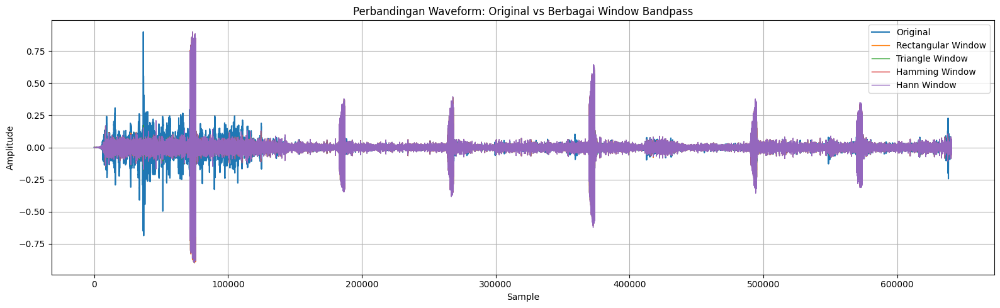

In [ ]:
import matplotlib.pyplot as plt

max_orig = np.max(np.abs(sig)) if np.max(np.abs(sig)) != 0 else 1
sig_norm = sig / max_orig * 0.9
plt.figure(figsize=(16, 5))

plt.plot(sig_norm, label="Original", linewidth=1.5)
for name, filtered in filtered_outputs.items():
    plt.plot(filtered, label=f"{name.capitalize()} Window", linewidth=1)

plt.title("Perbandingan Waveform: Original vs Berbagai Window Bandpass")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

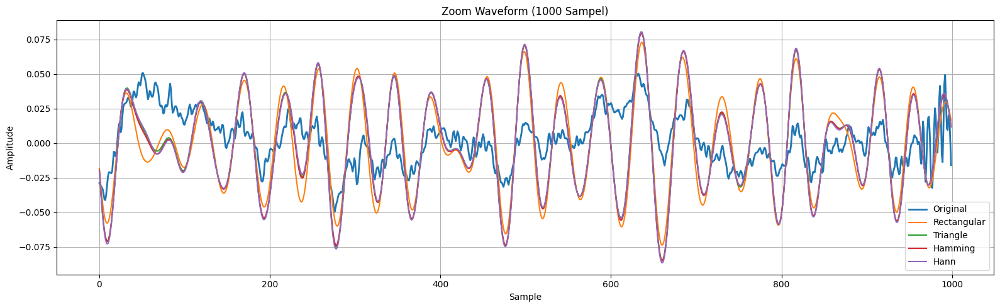

In [ ]:
start = 20000
end = start + 1000

plt.figure(figsize=(16, 5))

plt.plot(sig_norm[start:end], label="Original", linewidth=2)

for name, filtered in filtered_outputs.items():
    plt.plot(filtered[start:end], label=name.capitalize())

plt.title("Zoom Waveform (1000 Sampel)")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


**TAHAP 6b - BPF menggunakan Hamming**

In [ ]:
def design_bpf(fs, low_cut=650, high_cut=1600, numtaps=101):
    return firwin(numtaps, [low_cut, high_cut],
                  pass_zero=False, fs=fs, window="hamming")

def apply_bpf(signal, bpf):
    return filtfilt(bpf, 1.0, signal.astype(np.float32))


In [ ]:
print("Menggunakan file:", wav_file)

fs, data = read(wav_file)
sig = data.mean(axis=1) if data.ndim > 1 else data
sig = sig.astype(np.float32)

print("\nDEBUG SINYAL ASLI")
print("fs:", fs)
print("len(sig):", len(sig))
print("max(sig):", np.max(sig))
print("min(sig):", np.min(sig))

bpf = design_bpf(fs)

filtered_sig = apply_bpf(sig, bpf).astype(np.float32)

print("\nDEBUG SETELAH FILTER")
print("len(filtered):", len(filtered_sig))
print("max(filtered):", np.max(filtered_sig))
print("min(filtered):", np.min(filtered_sig))
print("Ada NaN?:", np.isnan(filtered_sig).any())
print("Ada Inf?:", np.isinf(filtered_sig).any())

max_val = np.max(np.abs(filtered_sig))
if max_val == 0:
    print("\n WARNING: Sinyal setelah filtering kosong! Tidak bisa normalisasi.")
    max_val = 1

filtered_norm = filtered_sig / max_val

output_filtered = "filtered_output.wav"
write(output_filtered, fs, (filtered_norm * 0.9).astype(np.float32))

print("\nFile audio tersimpan sebagai:", output_filtered)
print(" Audio SEBELUM Filter")
display(Audio(sig, rate=fs))

print("\n Memutar audio hasil BPF...")
Audio(filtered_norm, rate=fs)

Menggunakan file: rekaman sampel 4.wav

DEBUG SINYAL ASLI
fs: 48000
len(sig): 640512
max(sig): 7176.0
min(sig): -5481.0

DEBUG SETELAH FILTER
len(filtered): 640512
max(filtered): 1406.7225
min(filtered): -1403.5176
Ada NaN?: False
Ada Inf?: False

File audio tersimpan sebagai: filtered_output.wav
 Audio SEBELUM Filter



 Memutar audio hasil BPF...


**TAHAP 6c — Visualisasi sinyal setelah filtering**

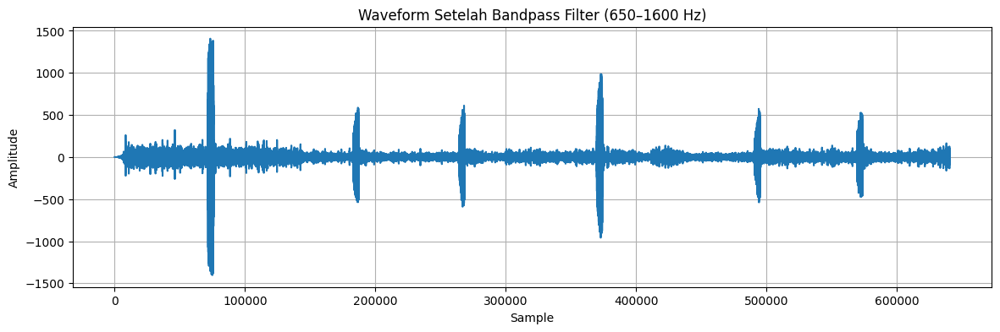

In [ ]:
bpf = design_bpf(fs)
sig_filt = apply_bpf(sig, bpf)
plt.figure(figsize=(14, 4))
plt.plot(sig_filt)
plt.title("Waveform Setelah Bandpass Filter (650–1600 Hz)")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()


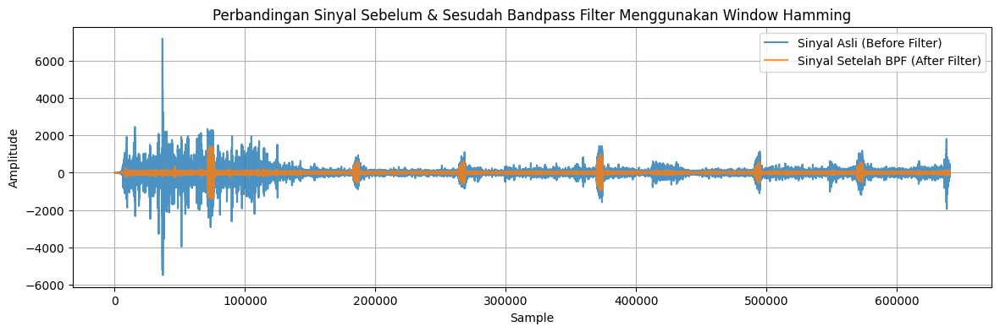

In [ ]:
bpf = design_bpf(fs)
sig_filt = apply_bpf(sig, bpf)
plt.figure(figsize=(14,4))
plt.plot(sig, label="Sinyal Asli (Before Filter)", alpha=0.8)
plt.plot(sig_filt, label="Sinyal Setelah BPF (After Filter)", alpha=0.8)
plt.title("Perbandingan Sinyal Sebelum & Sesudah Bandpass Filter Menggunakan Window Hamming")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.legend()
plt.show()

**TAHAP 7 — Visualisasi envelope + threshold 0.2 untuk segmentasi**

In [ ]:
def segment_tones(signal, fs, win_ms=20, threshold_ratio=0.2, min_len_ms=20):
    sig = signal.astype(np.float32)
    N = len(sig)

    win_size = int(fs * win_ms / 1000)
    if win_size < 1:
        win_size = 1

    kernel = np.ones(win_size) / win_size
    envelope = np.convolve(np.abs(sig), kernel, mode="same")

    th = envelope.max() * threshold_ratio
    mask = envelope > th

    segments = []
    in_seg = False
    start = 0

    for i, active in enumerate(mask):
        if active and not in_seg:
            in_seg = True
            start = i
        elif not active and in_seg:
            in_seg = False
            end = i
            if (end - start) >= int(fs * min_len_ms / 1000):
                segments.append((start, end))

    if in_seg:
        end = len(mask)
        if (end - start) >= int(fs * min_len_ms / 1000):
            segments.append((start, end))

    return segments


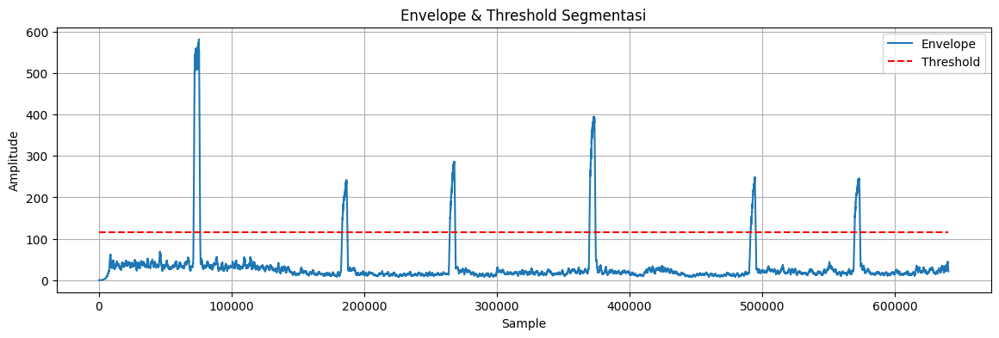

In [ ]:
win_ms = 20
win_size = int(fs * win_ms / 1000)
envelope = np.convolve(np.abs(sig_filt), np.ones(win_size)/win_size, mode="same")
threshold = envelope.max() * 0.2

plt.figure(figsize=(14, 4))
plt.plot(envelope, label="Envelope")
plt.hlines(threshold, 0, len(envelope), colors='r', linestyles='--', label="Threshold")
plt.title("Envelope & Threshold Segmentasi")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


**TAHAP 7b — Visualisasi envelope + threshold 0.3 untuk segmentasi**

In [ ]:
def segment_tones1(signal, fs, win_ms=20, threshold_ratio=0.3, min_len_ms=20):
    sig = signal.astype(np.float32)
    N = len(sig)

    win_size = int(fs * win_ms / 1000)
    if win_size < 1:
        win_size = 1

    kernel = np.ones(win_size) / win_size
    envelope = np.convolve(np.abs(sig), kernel, mode="same")

    th = envelope.max() * threshold_ratio
    mask = envelope > th

    segments = []
    in_seg = False
    start = 0

    for i, active in enumerate(mask):
        if active and not in_seg:
            in_seg = True
            start = i
        elif not active and in_seg:
            in_seg = False
            end = i
            if (end - start) >= int(fs * min_len_ms / 1000):
                segments.append((start, end))

    if in_seg:
        end = len(mask)
        if (end - start) >= int(fs * min_len_ms / 1000):
            segments.append((start, end))

    return segments


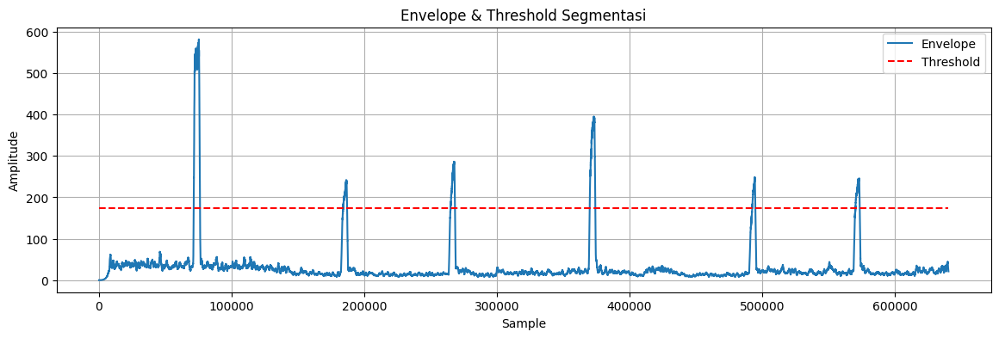

In [ ]:
win_ms = 20
win_size = int(fs * win_ms / 1000)
envelope = np.convolve(np.abs(sig_filt), np.ones(win_size)/win_size, mode="same")
threshold = envelope.max() * 0.3
plt.figure(figsize=(14, 4))
plt.plot(envelope, label="Envelope")
plt.hlines(threshold, 0, len(envelope), colors='r', linestyles='--', label="Threshold")
plt.title("Envelope & Threshold Segmentasi")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

**TAHAP 7b — Visualisasi envelope + threshold 0.5 untuk segmentasi**

In [ ]:
def segment_tones2(signal, fs, win_ms=20, threshold_ratio=0.5, min_len_ms=20):
    sig = signal.astype(np.float32)
    N = len(sig)

    win_size = int(fs * win_ms / 1000)
    if win_size < 1:
        win_size = 1

    kernel = np.ones(win_size) / win_size
    envelope = np.convolve(np.abs(sig), kernel, mode="same")

    th = envelope.max() * threshold_ratio
    mask = envelope > th

    segments = []
    in_seg = False
    start = 0

    for i, active in enumerate(mask):
        if active and not in_seg:
            in_seg = True
            start = i
        elif not active and in_seg:
            in_seg = False
            end = i
            if (end - start) >= int(fs * min_len_ms / 1000):
                segments.append((start, end))

    if in_seg:
        end = len(mask)
        if (end - start) >= int(fs * min_len_ms / 1000):
            segments.append((start, end))

    return segments


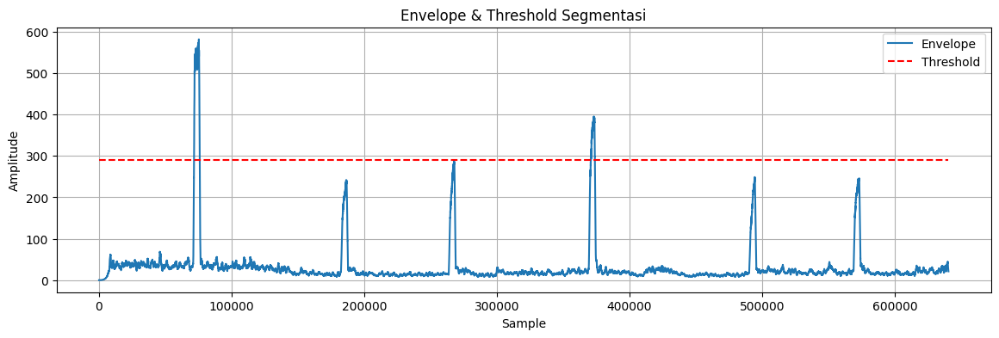

In [ ]:
win_ms = 20
win_size = int(fs * win_ms / 1000)
envelope = np.convolve(np.abs(sig_filt), np.ones(win_size)/win_size, mode="same")
threshold = envelope.max() * 0.5
plt.figure(figsize=(14, 4))
plt.plot(envelope, label="Envelope")
plt.hlines(threshold, 0, len(envelope), colors='r', linestyles='--', label="Threshold")
plt.title("Envelope & Threshold Segmentasi")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

**TAHAP 7c — Perbandingan Plot FFT 3 Threshold**


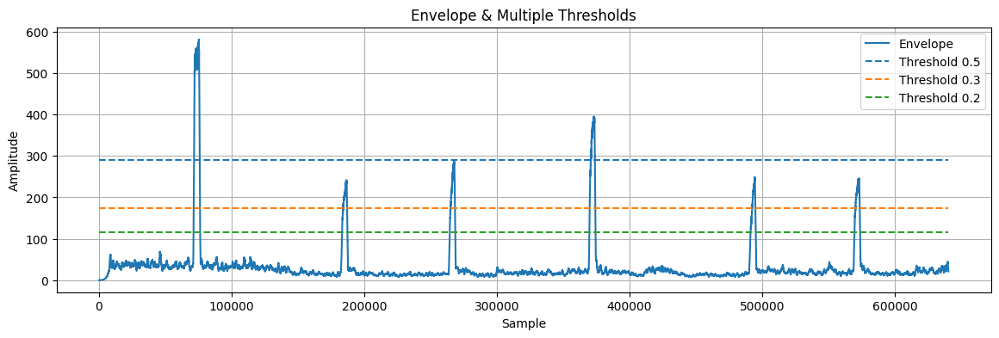

In [ ]:
thresholds = [0.5, 0.3, 0.2]
cmap = plt.cm.tab10

plt.figure(figsize=(14, 4))
plt.plot(envelope, label="Envelope")

for i, t in enumerate(thresholds):
    th = envelope.max() * t
    plt.hlines(
        th, 0, len(envelope),
        colors=cmap(i),
        linestyles='--',
        label=f"Threshold {t}"
    )

plt.title("Envelope & Multiple Thresholds")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

**TAHAP 8 — Deteksi frekuensi per segmen (FFT) untuk 3 threshold**


THRESHOLD 0.2


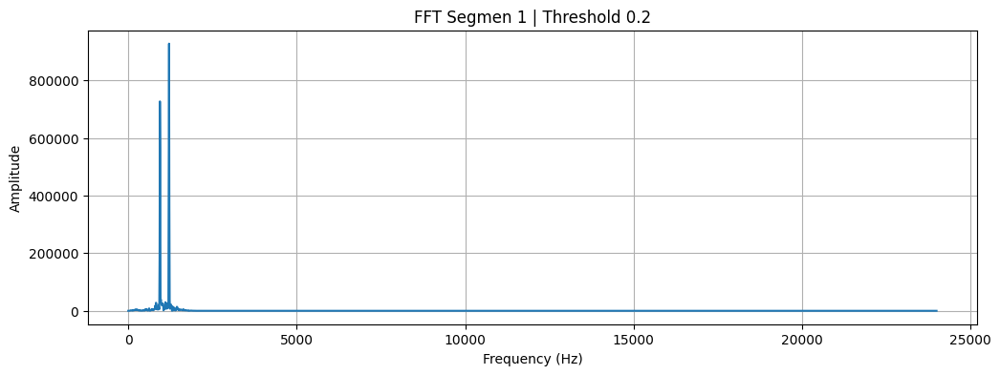

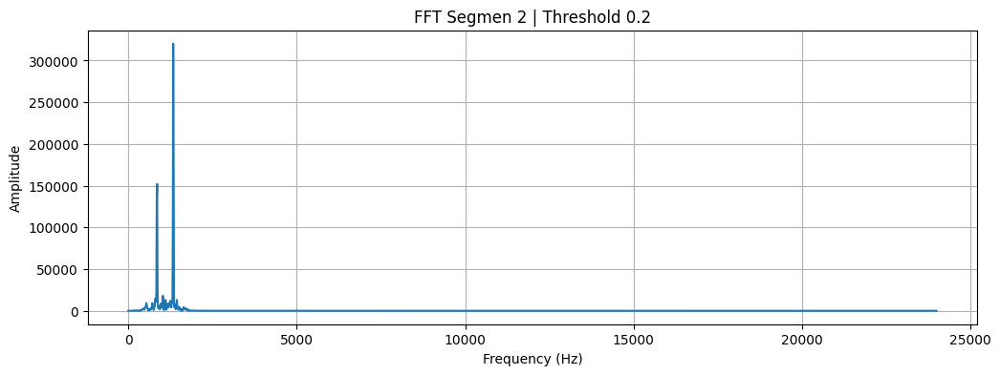

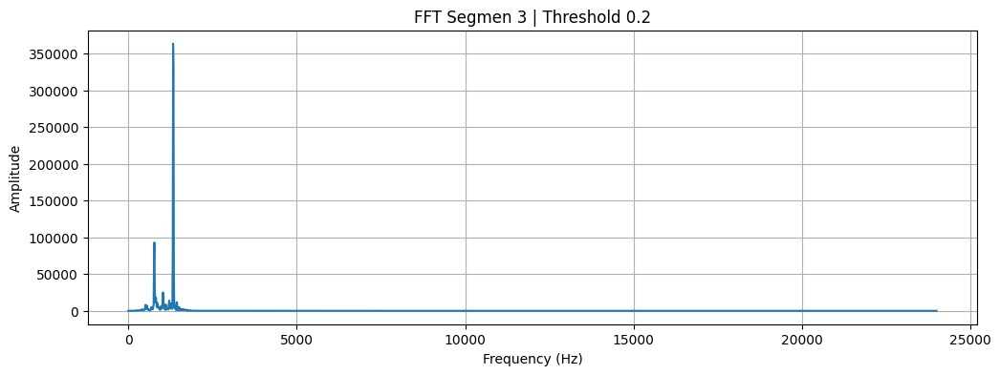

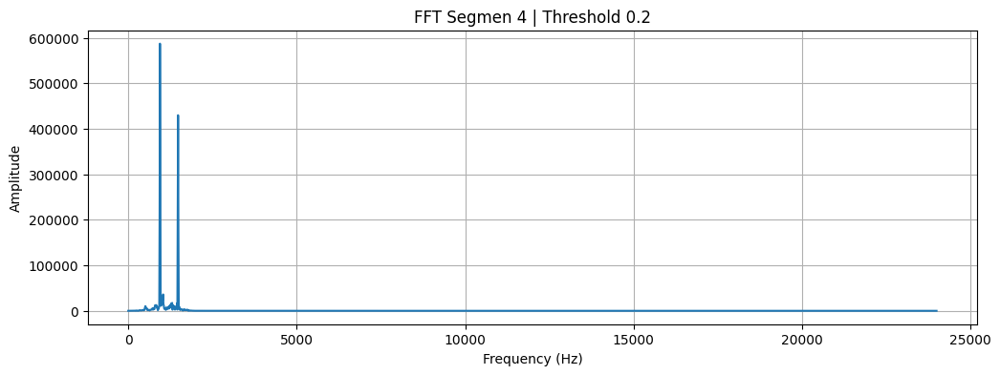

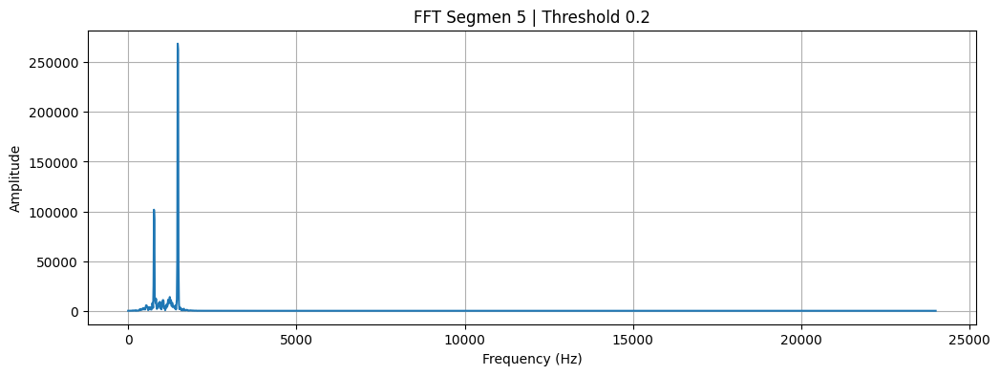

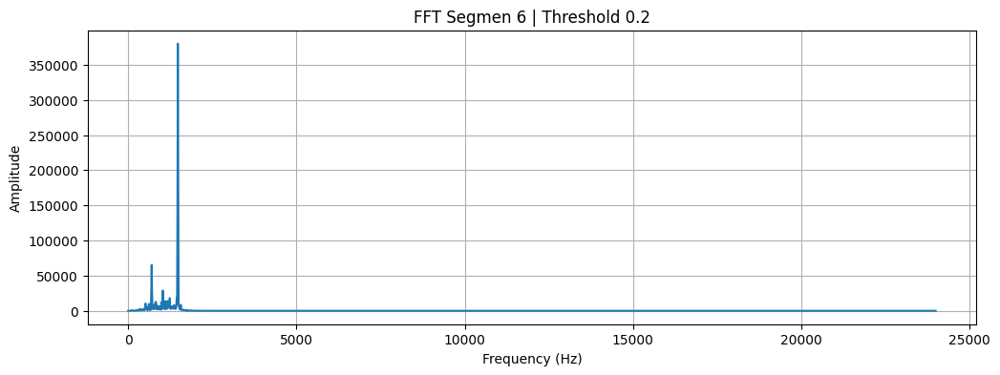

In [ ]:
thresholds = [0.2]

for th in thresholds:
    print(f"\nTHRESHOLD {th}")

    segments = segment_tones(
        sig_filt,
        fs,
        threshold_ratio=th
    )

    for i, (start, end) in enumerate(segments):
        seg = sig_filt[start:end]

        N = len(seg)
        if N == 0:
            continue

        freqs = fftfreq(N, 1/fs)
        fft_vals = np.abs(fft(seg * np.hamming(N)))

        mask = freqs >= 0
        freqs = freqs[mask]
        fft_vals = fft_vals[mask]

        plt.figure(figsize=(12, 4))
        plt.plot(freqs, fft_vals)
        plt.title(f"FFT Segmen {i+1} | Threshold {th}")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.show()



 THRESHOLD 0.3


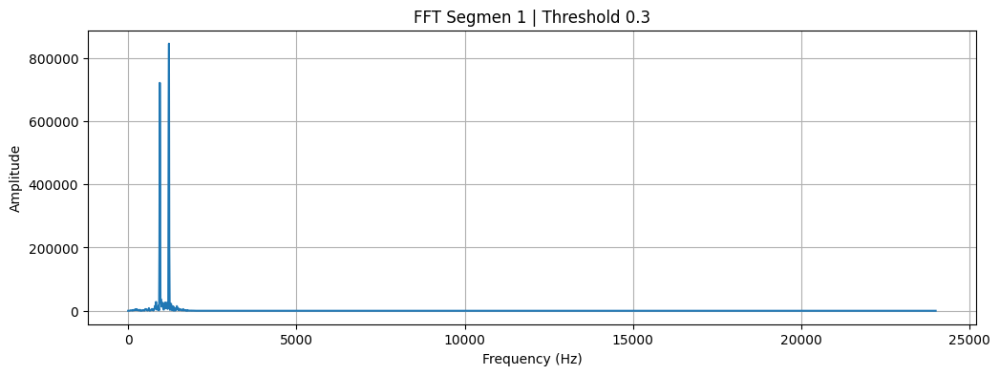

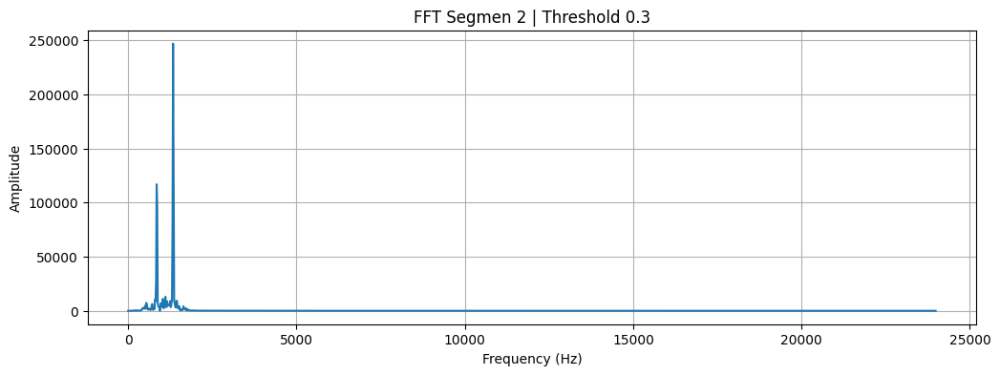

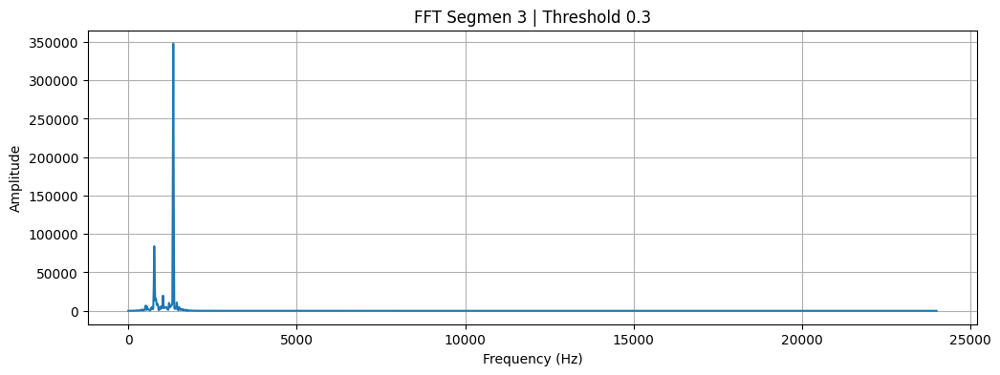

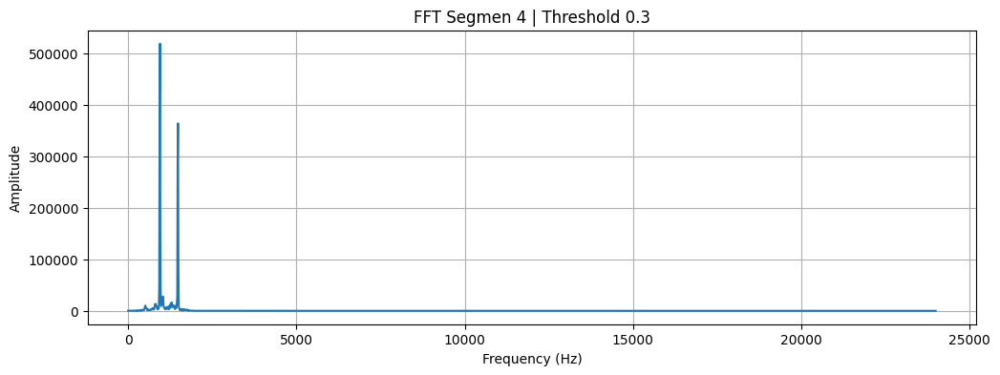

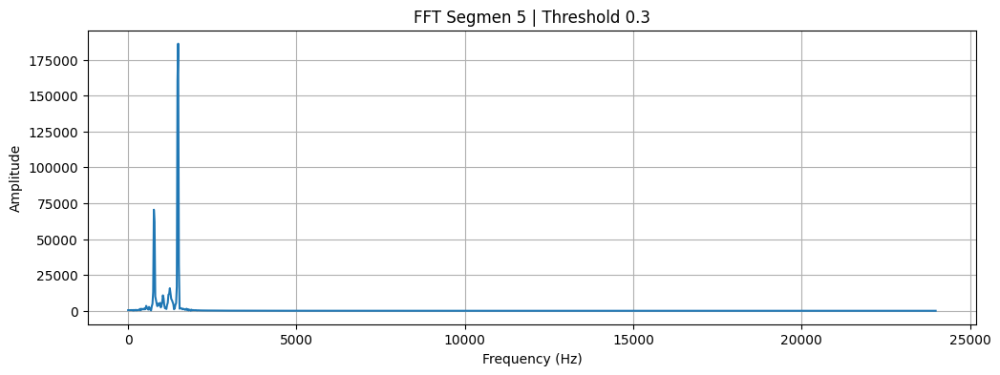

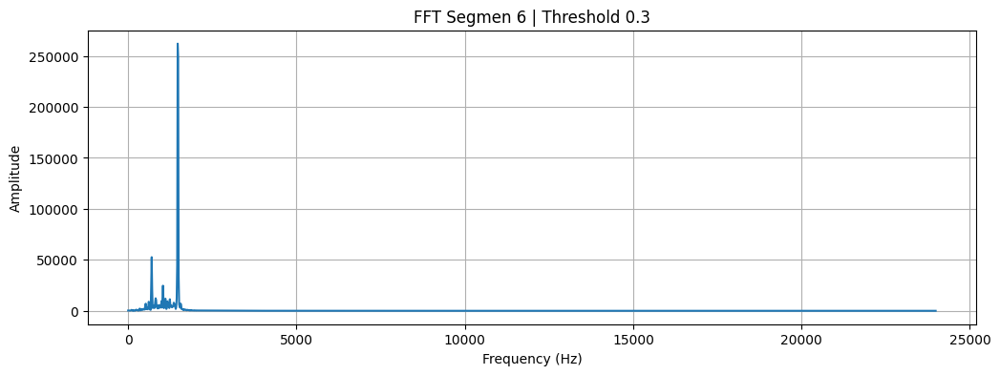

In [ ]:
thresholds = [0.3]

for th in thresholds:
    print(f"\n THRESHOLD {th}")

    segments = segment_tones(
        sig_filt,
        fs,
        threshold_ratio=th
    )

    for i, (start, end) in enumerate(segments):
        seg = sig_filt[start:end]

        N = len(seg)
        if N == 0:
            continue

        freqs = fftfreq(N, 1/fs)
        fft_vals = np.abs(fft(seg * np.hamming(N)))

        mask = freqs >= 0
        freqs = freqs[mask]
        fft_vals = fft_vals[mask]

        plt.figure(figsize=(12, 4))
        plt.plot(freqs, fft_vals)
        plt.title(f"FFT Segmen {i+1} | Threshold {th}")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.show()



THRESHOLD 0.5


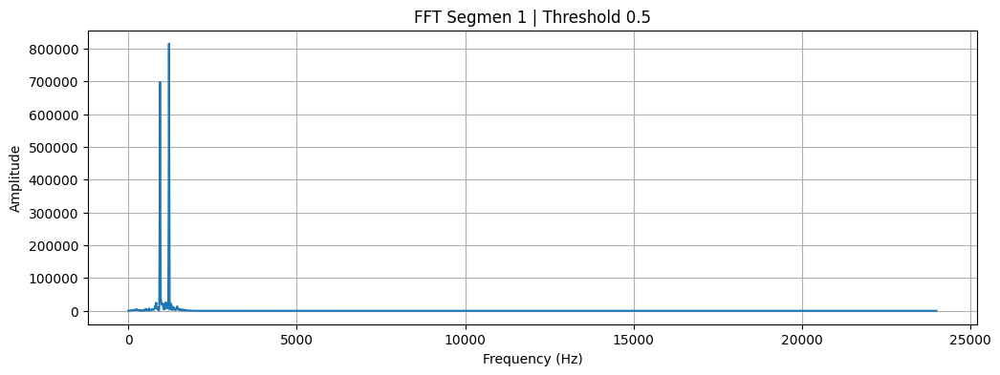

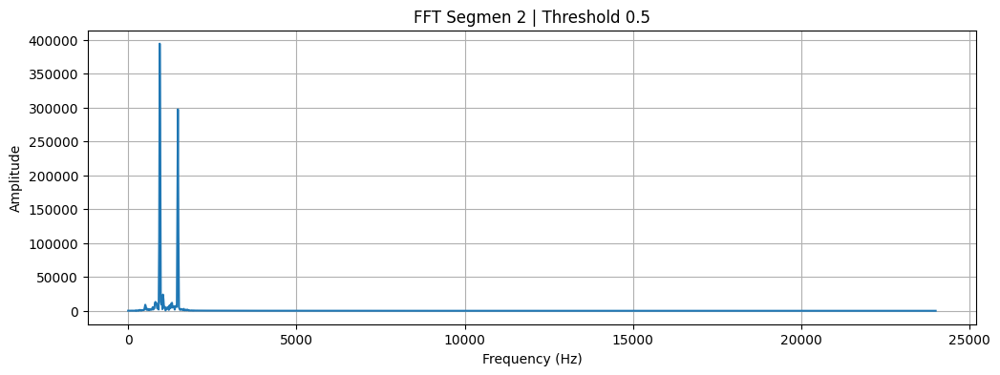

In [ ]:
thresholds = [0.5]

for th in thresholds:
    print(f"\nTHRESHOLD {th}")

    segments = segment_tones(
        sig_filt,
        fs,
        threshold_ratio=th
    )

    for i, (start, end) in enumerate(segments):
        seg = sig_filt[start:end]

        N = len(seg)
        if N == 0:
            continue

        freqs = fftfreq(N, 1/fs)
        fft_vals = np.abs(fft(seg * np.hamming(N)))

        mask = freqs >= 0
        freqs = freqs[mask]
        fft_vals = fft_vals[mask]

        plt.figure(figsize=(12, 4))
        plt.plot(freqs, fft_vals)
        plt.title(f"FFT Segmen {i+1} | Threshold {th}")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.show()


In [ ]:
for t in [0.5, 0.3, 0.2]:
    segments = segment_tones2(
        signal=sig_filt,
        fs=fs,
        threshold_ratio=t
    )
    print(f"Threshold {t}: jumlah segmen = {len(segments)}")

Threshold 0.5: jumlah segmen = 2
Threshold 0.3: jumlah segmen = 6
Threshold 0.2: jumlah segmen = 6


**TAHAP 8 — Deteksi frekuensi per segmen (FFT)**

In [ ]:
def nearest_standard(freq, standards, tol=FREQ_TOL):
    diffs = np.abs(standards - freq)
    idx = np.argmin(diffs)
    return standards[idx] if diffs[idx] <= tol else None


def detect_tone_freqs(segment, fs):
    sig = segment.astype(np.float32)
    N = len(sig)

    if N == 0:
        return None, None

    window = np.hamming(N)
    fft_vals = np.abs(fft(sig * window))
    freqs = fftfreq(N, 1/fs)
    mask = freqs >= 0
    fft_vals, freqs = fft_vals[mask], freqs[mask]

    low_band = (freqs >= 600) & (freqs <= 1000)
    high_band = (freqs >= 1100) & (freqs <= 1800)

    if not np.any(low_band) or not np.any(high_band):
        return None, None

    low_freq = freqs[low_band][np.argmax(fft_vals[low_band])]
    high_freq = freqs[high_band][np.argmax(fft_vals[high_band])]
    return low_freq, high_freq


**Mapping Frekuensi ke Tombol DTMF**

In [ ]:
def map_to_dtmf_key(low_freq, high_freq):
    low_std = nearest_standard(low_freq, LOW_FREQS)
    high_std = nearest_standard(high_freq, HIGH_FREQS)
    if low_std is None or high_std is None:
        return None
    return DTMF_TABLE.get((int(low_std), int(high_std)))

**TAHAP 9 — Pipeline decoding lengkap perbandingan 3 threshold**

In [ ]:
def decode_dtmf_from_wav_compare(wav_path, thresholds=[0.5, 0.3, 0.2]):
    print("Memproses:", wav_path)

    fs, data = read(wav_path)
    sig = data.mean(axis=1) if data.ndim > 1 else data.astype(np.float32)

    bpf = design_bpf(fs)
    sig_filt = apply_bpf(sig, bpf)

    results = {}

    for th in thresholds:
        print("\n" + "="*40)
        print(f"THRESHOLD RATIO = {th}")

        segments = segment_tones(
            sig_filt,
            fs,
            threshold_ratio=th
        )

        print("Jumlah segmen:", len(segments))

        hasil = []

        for i, (start, end) in enumerate(segments, 1):
            seg = sig_filt[start:end]
            low_f, high_f = detect_tone_freqs(seg, fs)
            key = map_to_dtmf_key(low_f, high_f)

            print(f"\nSegmen {i}")
            print("Low :", low_f)
            print("High:", high_f)
            print("Key :", key)

            if key:
                hasil.append(key)

        hasil_str = "".join(hasil)
        print("\nHasil Akhir:", hasil_str)

        results[th] = hasil_str

    return results


In [ ]:
results = decode_dtmf_from_wav_compare(wav_file)

print("\nRINGKASAN PERBANDINGAN")
for th, res in results.items():
    print(f"Threshold {th}: {res}")


Memproses: rekaman sampel 4.wav

THRESHOLD RATIO = 0.5
Jumlah segmen: 2

Segmen 1
Low : 942.0457169244978
High: 1208.0350958208267
Key : *

Segmen 2
Low : 938.0589599205035
High: 1478.6353097052004
Key : #

Hasil Akhir: *#

THRESHOLD RATIO = 0.3
Jumlah segmen: 6

Segmen 1
Low : 939.7894736842106
High: 1212.6315789473686
Key : *

Segmen 2
Low : 846.1016949152543
High: 1334.2372881355932
Key : 8

Segmen 3
Low : 770.2089009990917
High: 1336.9663941871027
Key : 5

Segmen 4
Low : 945.868945868946
High: 1481.4814814814818
Key : #

Segmen 5
Low : 763.542562338779
High: 1485.8125537403268
Key : 6

Segmen 6
Low : 699.0291262135922
High: 1470.873786407767
Key : 3

Hasil Akhir: *85#63

THRESHOLD RATIO = 0.2
Jumlah segmen: 6

Segmen 1
Low : 939.2777889852734
High: 1210.409521888239
Key : *

Segmen 2
Low : 857.7810871183917
High: 1334.3261355174982
Key : 8

Segmen 3
Low : 775.5003617072583
High: 1331.0827103930553
Key : 5

Segmen 4
Low : 940.7710531983632
High: 1478.3545121688564
Key : #

Segmen 5
